# T2D and non-T2D Classification based on Unstructured Clinical Notes
 ###  Xiaowen Li

###  supervisor: Yalu Wen

# Import Libraries

In [8]:
from __future__ import division
import pandas as pd
import numpy as np 
from pandas import read_excel
import nltk, re, pprint, sys,random,os, math, string
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
from collections import Counter
import seaborn as sns

from nltk import word_tokenize
from nltk.stem import WordNetLemmatizer 
from nltk.tag import pos_tag
from nltk.corpus import wordnet
from nltk.corpus import stopwords
#from yellowbrick.text import FreqDistVisualizer
from collections import defaultdict

from sklearn.feature_extraction import text
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.feature_selection import SelectKBest, SelectFromModel
from sklearn.feature_selection import chi2
from sklearn.calibration import CalibratedClassifierCV
from sklearn import metrics
from sklearn.metrics import confusion_matrix,log_loss
from sklearn.metrics import make_scorer
from sklearn.metrics import roc_auc_score, cohen_kappa_score
from sklearn.metrics import precision_score, recall_score 
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score
from sklearn.utils.multiclass import unique_labels
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import SGDClassifier, ElasticNet
from sklearn.linear_model import LogisticRegressionCV, LogisticRegression
from sklearn.svm import SVC
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier, VotingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.pipeline import Pipeline
from sklearn.multiclass import OutputCodeClassifier
from sklearn.multiclass import OneVsOneClassifier
from sklearn.multiclass import OneVsRestClassifier

from imblearn.pipeline import make_pipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler, ADASYN
from imblearn.under_sampling import NearMiss, RandomUnderSampler

# Loading the data

In [9]:
# read in the clinical data set.
warnings.filterwarnings("ignore", category= UserWarning)

data_original = pd.read_excel('dataset.xlsx')
# convert the file into dataframe
# select the columns we need: 'Comorbidity' and 'Coding'.
data = pd.DataFrame(data_original)[['Comorbidity', 'Coding']]
print(data.shape)
data.head()

(303341, 2)


,Comorbidity,Coding
0,Comorbidity,Comorbidity
1,None,None
2,Multiple recent GAs OK: vancomycin and ceftria...,"vancomycin, ceftriaxone"
3,Type 2 DM: on GIK infusion (also on metformin),Type 2 diabetes
4,"Hypertension, dyslipidaemia: cilazapril, aspir...","Hypertension, dyslipidemia"


# Step1 - Data Exploration and Preparation

In [10]:
data.info()

# romove the data that 'Comorbidity' and 'Coding' are both missing.
new_data = data.dropna(axis=0, how='all')
# comparing sizes of data frames 
print("\nOld data frame length:", len(data),
      "\nNew data frame length:",  len(new_data)) 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303341 entries, 0 to 303340
Data columns (total 2 columns):
Comorbidity    297998 non-null object
Coding         300790 non-null object
dtypes: object(2)
memory usage: 4.6+ MB

Old data frame length: 303341 
New data frame length: 303287


# Step2 - Label  T2D and non-T2D according to "Coding"
Due to this is an unlabelled dataset, a rule-based NLP method is applied to pretrain this data to pre label the T2D and non-T2D first based on the 'Coding'. The coding includes missing values and 0 from which we could not determine the patient is a T2D or a non-T2D. Hence we replace it with ' '. Hence, we will preprocess 'Coding' first.

At first, we normalize the 'Coding' column.

     converting all letters to lower case
     removing numbers excluding the number 2.
     removing punctuations, accent marks and other diacritics
     lemmatize words.

In [11]:
def text_clean(text):
    '''
    replace punctuations and number with spaces.
    remove anything but characters and spaces.
    convert text into lower case.
    '''
    punc_list = string.punctuation + '013456789'
    t = str.maketrans(dict.fromkeys(punc_list, ' '))
    text = text.str.lower().str.translate(t)
    return text

# normalize 'Coding' notes.
df = new_data.copy()
df['Coding_clean'] = text_clean(df.Coding)
df.Coding_clean = df.Coding_clean.replace(np.NaN, ' ')
df.Coding_clean = df.Coding_clean.replace('', ' ')
df.Coding_clean = [re.sub(' +', ' ',e) for e in df.Coding_clean]

In [12]:
# Lemmatize with POS Tag
def get_wordnet_pos(word):
    """Map POS tag to first character lemmatize() accepts"""
    tag = nltk.pos_tag([word])[0][1][0].upper()
    tag_dict = {"J": wordnet.ADJ,
                "N": wordnet.NOUN,
                "V": wordnet.VERB,
                "R": wordnet.ADV}
    return tag_dict.get(tag, wordnet.NOUN)

#lemmatize Words
lemma = WordNetLemmatizer()

#Lemmatize a Sentence with the appropriate POS tag
def lemmatize_text(text):
    return [lemma.lemmatize(w, get_wordnet_pos(w)) for w in text]

In [13]:
#tokenize text
df.Coding_clean = df.Coding_clean.apply(word_tokenize)
# Lemmatize list of words and join
df.Coding_clean  = df.Coding_clean.apply(lemmatize_text)
#join the words in 'Coding'
df.Coding_clean = df.Coding_clean.str.join(' ')

In [14]:
#rword list.
word_list_T2D = [r'\b(t|type)\s*(2|ii|two)\s*(diabetes|dm|d)\b', 
                 r'\b(diabetes|dm)\s*(type|t)?\s*(2|ii|two)\b']
df.Coding_clean = df.Coding_clean.str.replace("|".join(word_list_T2D), 't2diabetes')
df.Coding_clean = df.Coding_clean.str.replace(r'\b(denies|deny|no|nil|none|non)\s*t2diabetes','non_t2d')

df['T2D_status'] =  np.where(df.Coding_clean.str.contains('t2diabetes'), 'T2D', 'NON_T2D')

In [15]:
print(df.T2D_status.value_counts())

NON_T2D    299104
T2D          4183
Name: T2D_status, dtype: int64


In [16]:
# Create a varibale 'output_label' 
mappings = {'NON_T2D': 0, 'T2D': 1}
df['output_label'] = df['T2D_status'].map(mappings)

In [17]:
np.random.seed(50)
df.sample(5)

,Comorbidity,Coding,Coding_clean,T2D_status,output_label
261224,? recent anaphylaxis/Tryptase awaited,? recent anaphylaxis/Tryptase awaited,recent anaphylaxis tryptase await,NON_T2D,0
272635,NIDDM HPT,Type 2 diabetes HPT,t2diabetes hpt,T2D,1
103300,type 2 DM poor control,type 2 diabetes poor control,t2diabetes poor control,T2D,1
12993,G+H available,G+H available,g h available,NON_T2D,0
18153,Tramadol/NSAIDs - nausea,Tramadol/non-steroidal anti-inflammatory drugs...,tramadol non steroidal anti inflammatory drug ...,NON_T2D,0


# Step3 - Preprocess Comorbidity
we need to preprocess the Comorbidity notes and create the Bag-of-Words(BOW).
The main idea is breaking up each text into individual words and then count the frequency of each word occurs.
Now, we need to preprocess the 'Comorbidity' notes. The steps are similar as we done to preprocess the 'Coding'.

Preprocess the 'Comorbidity' notes

     converting all letters to lower case
     removing numbers excluding the number 2.
     removing punctuations, accent marks and other diacritics


Then, the notes are tokenized by tokenizer (word_tokenize( )), remove stop words and count the frequency using TfidfVectorizer. We could notice that there are a lot of words occuring most frequently but giving little information, such as words 'the', 'and', 'of', 'to', etc. We call them stop words. We need to remove stop words, sparse terms, and particular words.

## 'Comorbidity' notes cleaning and normalization

In [18]:
comor = df.copy()[['Comorbidity','Coding','T2D_status', 'output_label']]
# remove missing values
comor_new = comor[comor.Comorbidity.isnull() == False]
# comparing sizes of data frames 
print("Old data frame length:", len(comor),
      "\nNew data frame length:",  len(comor_new)) 
print(comor_new.T2D_status.value_counts())

Old data frame length: 303287 
New data frame length: 297998
NON_T2D    293815
T2D          4183
Name: T2D_status, dtype: int64


In [19]:
warnings.filterwarnings("ignore")
# normalise using text_clean() function we defined before.
comor_new['Comorbidity'] = text_clean(comor_new.Comorbidity)
comor_new['Comorbidity'] = [re.sub(' +', ' ', str(e)) for e in comor_new.Comorbidity]

# remove the white space
comor_new = comor_new[comor_new.Comorbidity != ' ']
print(len(comor_new))
print(comor_new.T2D_status.value_counts())

297936
NON_T2D    293753
T2D          4183
Name: T2D_status, dtype: int64


In [20]:
comor_new['final_Comor'] =comor_new.Comorbidity.apply(word_tokenize) 
# Lemmatize Comorbidity and join
comor_new['final_Comor'] = comor_new['final_Comor'].apply(lemmatize_text)
comor_new['final_Comor'] = comor_new['final_Comor'].str.join(' ')

## Partition training and test sets
In order to avoid overfitting, Cross validation will be tried. We would like to partition the original dataset into training test set.

20% of the dataset will be drawn randomly from the original dataset to test and compare different models. Others will be split into 10 kolds and to apply cross validation method.

(the random_state = 42)

before partition, the duplicates are removed from the dataset.

In [21]:
# remove the duplicate records in comorbidity
print(comor_new.shape)
print(comor_new.drop_duplicates(subset = 'Comorbidity', keep='last').shape)
comor_new = comor_new.drop_duplicates(subset = 'Comorbidity', keep='last')
print(len(comor_new))

(297936, 5)
(266486, 5)
266486


In [22]:
# shuffle the samples
np.random.seed(42)
comor_radom = comor_new.sample(n = len(comor_new), random_state = 42)
comor_radom = comor_radom.reset_index(drop = True)

# Save 20% of the data as the test data
# use the rest of the data as train and validation set.
test = comor_radom.sample(frac=0.20,random_state = 42)
train = comor_radom.drop(test.index)

print('===training_set========')
print(train.T2D_status.value_counts())

print('===test_set========')
print(test.T2D_status.value_counts())

===training_set========
NON_T2D    210413
T2D          2776
Name: T2D_status, dtype: int64
===test_set========
NON_T2D    52593
T2D          704
Name: T2D_status, dtype: int64


# Step5 - classification
This step is to classify diabetes status using machine learning methods. including:
  1. logisitc regression
  2. linear SVM
  3. Random Forest
  4. naive bayes
  5. Multi-layer perceptron
  6. voting classifier

For each method, it includes:
1. feature engine
2. feature selection
3. data balancing
4. hyperparameter tuning
5. prediction

each step, the performance will be compared with the previous one.

    
## explore the most frequent words in the total data set and each class.
the words occur frequently sometimes will have a high correlation with the targets. however, the words like 'a', 'the', 'and', etc. just are used commonly but providing nothing information, whic hare defined as stopwords. They will be considered as the 'noise' words. hence, we will check the most frequent words first and to try to remove 'noise'. There is an inbuilt sropwords corpus in nltk, we will first remove these words and to check whether there exist other 'noise' words.

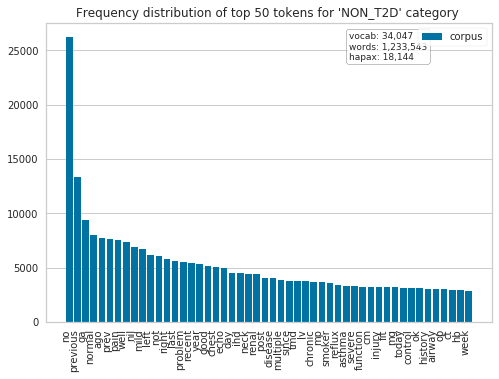

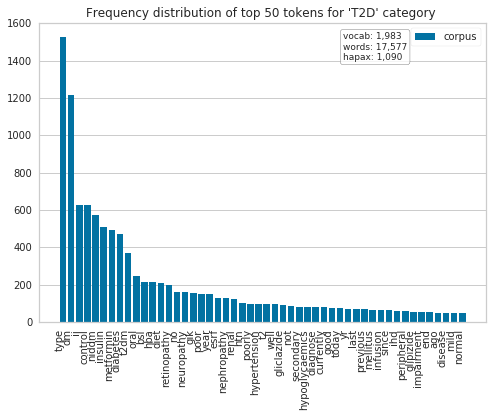

In [23]:
from yellowbrick.text import FreqDistVisualizer
from sklearn.feature_extraction.text import CountVectorizer
from nltk.corpus import stopwords
warnings.filterwarnings("ignore", category= UserWarning)

stopwords = stopwords.words('english')
STOP_WORDS = set(stopwords) - set(["never", "no", "not"]) 

X= train.final_Comor
y = train.T2D_status

classes = np.array(['NON_T2D', 'T2D'])

T2DorNot = defaultdict(list)
for text, label in zip(X,y):
    T2DorNot[label].append(text)
    
# Loop through the categories
for cat in classes:
    vectorizer  = CountVectorizer(stop_words = STOP_WORDS)
    docs        = vectorizer.fit_transform(text for text, label in zip(X,y) if label == cat)
    features    = vectorizer.get_feature_names()

    fig, ax = plt.subplots()

    # Create a title
    cat_title = "Frequency distribution of top 50 tokens for '{}' category ".format(cat)

    # Pass the title into the Visualizer using the `title` param
    visualizer = FreqDistVisualizer(features=features, ax=ax, title=cat_title, orient='v')
    visualizer.fit(docs)
    visualizer.poof()

Some words seem weird, the fiftieth most frequent word 'np', the 'yr', 'hx', 'otherwise', 'dm', 'fvc'. After checking the original text, the 'np','dm','fvc' are some didease or test index, hence we should not remove them. 

After checking other words( not shown in the figures). The words 'year', 'yr', 'poorly', 'since', 'last', 'otherwise', 'usually', 'slightly', 'else', 'week', 'month', 'day','recent' are removed. Then the BOWs is updated.

In [24]:
from nltk.corpus import stopwords
warnings.filterwarnings("ignore", category= UserWarning)
stopwords = stopwords.words('english')
STOP_WORDS = set(stopwords) - set(["never", "no", "not"]) 
STOP_WORDS |= {'year', 'yr', 'poorly', 'since', 'last', 'otherwise', 
              'usually','slightly', 'else', 'week', 'month', 'day','recent'}


X_train = train.final_Comor.values
y_train = train.output_label.values

X_test = test.final_Comor.values
y_test = test.output_label.values

def cv(splits, X, Y, pipeline):
    kfold = StratifiedKFold(n_splits = splits, shuffle = True, random_state= 42)
    precision = []
    recall = []
    f = []
    kappa = []
    roc_auc =[]
    for train, test in kfold.split(X, Y):
        clf_fit = pipeline.fit(X[train], Y[train])
        prediction = clf_fit.predict(X[test])
        scores = clf_fit.score(X[test],Y[test])
        
        precision.append(precision_score(Y[test], prediction)*100)
        recall.append(recall_score(Y[test], prediction)*100)
        f.append(f1_score(Y[test], prediction)*100)
        kappa.append(cohen_kappa_score(Y[test], prediction)*100)
        roc_auc.append(roc_auc_score(Y[test], prediction)*100)

    print("precision: %.2f%% (+/- %.2f%%)" % (np.mean(precision), np.std(precision)))
    print("recall: %.2f%% (+/- %.2f%%)" % (np.mean(recall), np.std(recall)))
    print("f1 score: %.2f%% (+/- %.2f%%)" % (np.mean(f), np.std(f)))
    #print("roc_auc score: %.2f%% (+/- %.2f%%)" % (np.mean(rocauc), np.std(rocauc)))
    print("kappa score: %.2f%% (+/- %.2f%%)" % (np.mean(kappa), np.std(kappa)))
    print("roc_auc score: %.2f%% (+/- %.2f%%)" % (np.mean(roc_auc), np.std(roc_auc)))
    

## 1. Baseline Model -- Logistic Regression

### a) LR with unigram

In [18]:
tfidf_unigram = TfidfVectorizer(stop_words = STOP_WORDS, ngram_range =(1,1))

lr_unigram = LogisticRegression(random_state = 42)
pipe_lr_unigram = make_pipeline(tfidf_unigram, lr_unigram)

pipe_lr_unigram.fit(X_train, y_train)
y_pred_unigram = pipe_lr_unigram.predict(X_test)

# merge the prediction results as a dataframe named result.
# Create a zipped list of tuples from above lists
zippedList = list(zip(y_test, y_pred_unigram))
# Create a dataframe from zipped list
result = pd.DataFrame(zippedList, columns = ['output_label', 'pred_status']) 
print('========== prediciton of original LR --unigram ==========')
print(metrics.classification_report(result['output_label'],result['pred_status'], digits=4))
print("kappa score:", cohen_kappa_score(result['output_label'],result['pred_status'])*100)
print("roc_auc score:", roc_auc_score(result['output_label'],result['pred_status'])*100)

========== prediciton of original LR --unigram ==========
              precision    recall  f1-score   support

           0     0.9982    0.9993    0.9987     52593
           1     0.9399    0.8665    0.9017       704

    accuracy                         0.9975     53297
   macro avg     0.9691    0.9329    0.9502     53297
weighted avg     0.9974    0.9975    0.9975     53297

kappa score: 90.0438275187501
roc_auc score: 93.28678645879248


### b) LR with bigrams

In [19]:
tfidf_bigram = TfidfVectorizer(stop_words = STOP_WORDS, ngram_range =(1,2))

lr = LogisticRegression(random_state = 42)
pipe_lr_bigram = make_pipeline(tfidf_bigram, lr)

pipe_lr_bigram.fit(X_train, y_train)
y_pred_bigram = pipe_lr_bigram.predict(X_test)

# merge the prediction results as a dataframe named result.
# Create a zipped list of tuples from above lists
zippedList = list(zip(y_test, y_pred_bigram))
# Create a dataframe from zipped list
result = pd.DataFrame(zippedList, columns = ['output_label', 'pred_status']) 
print('========== prediciton of original LR --bigram ==========')
print(metrics.classification_report(result['output_label'],result['pred_status'], digits=4))
print("kappa score:", cohen_kappa_score(result['output_label'],result['pred_status'])*100)
print("roc_auc score:", roc_auc_score(result['output_label'],result['pred_status'])*100)

========== prediciton of original LR --bigram ==========
              precision    recall  f1-score   support

           0     0.9982    0.9992    0.9987     52593
           1     0.9338    0.8622    0.8966       704

    accuracy                         0.9974     53297
   macro avg     0.9660    0.9307    0.9476     53297
weighted avg     0.9973    0.9974    0.9973     53297

kappa score: 89.5274509214439
roc_auc score: 93.0699154895311


### c) LR with trigrams

In [20]:
tfidf_trigram = TfidfVectorizer(stop_words = STOP_WORDS, ngram_range =(1,3))

lr = LogisticRegression(random_state = 42)
pipe_lr_trigram = make_pipeline(tfidf_trigram, lr)

pipe_lr_trigram.fit(X_train, y_train)
y_pred_trigram = pipe_lr_trigram.predict(X_test)

# merge the prediction results as a dataframe named result.
# Create a zipped list of tuples from above lists
zippedList = list(zip(y_test, y_pred_trigram))
# Create a dataframe from zipped list
result = pd.DataFrame(zippedList, columns = ['output_label', 'pred_status']) 
print('========== prediciton of original LR --trigram ==========')
print(metrics.classification_report(result['output_label'],result['pred_status'], digits=4))
print("kappa score:", cohen_kappa_score(result['output_label'],result['pred_status'])*100)
print("roc_auc score:", roc_auc_score(result['output_label'],result['pred_status'])*100)

========== prediciton of original LR --trigram ==========
              precision    recall  f1-score   support

           0     0.9984    0.9991    0.9987     52593
           1     0.9266    0.8793    0.9023       704

    accuracy                         0.9975     53297
   macro avg     0.9625    0.9392    0.9505     53297
weighted avg     0.9974    0.9975    0.9975     53297

kappa score: 90.1059751791767
roc_auc score: 93.91648403563903


Comments:
            
     unigram: the kappa score of the logistic regression with unigram is 90.0438% and the roc_auc score is 93.2867&
     bigram: kappa score is kappa score: 89.5275% roc_auc score: 93.0699%.
     trigram: kappa score: 90.1060% roc_auc score: 93.9165%

hence, the trigrams model is determined.

### d) Logistic Regression with Feature Selection

In [21]:
tfidf_trigram = TfidfVectorizer(stop_words = STOP_WORDS, ngram_range =(1,3))
lr_elastic = LogisticRegression(random_state = 42, solver='saga', penalty = 'elasticnet',l1_ratio =0.5)

lr_elastic_pipe = make_pipeline(tfidf_trigram,lr_elastic) 

lr_elastic_pipe.fit(X_train, y_train)
y_pred = lr_elastic_pipe.predict(X_test)


# merge the prediction results as a dataframe named result.
# Create a zipped list of tuples from above lists
zippedList = list(zip(y_test, y_pred))
# Create a dataframe from zipped list
result = pd.DataFrame(zippedList, columns = ['output_label', 'pred_status']) 
print('========== LR with feature selection --trigram ==========')
print(metrics.classification_report(result['output_label'],result['pred_status'], digits=4))
print("kappa score:", cohen_kappa_score(result['output_label'],result['pred_status'])*100)
print("roc_auc score:", roc_auc_score(result['output_label'],result['pred_status'])*100)

========== LR with feature selection --trigram ==========
              precision    recall  f1-score   support

           0     0.9987    0.9990    0.9989     52593
           1     0.9245    0.9048    0.9146       704

    accuracy                         0.9978     53297
   macro avg     0.9616    0.9519    0.9567     53297
weighted avg     0.9977    0.9978    0.9978     53297

kappa score: 91.34418292652852
roc_auc score: 95.19204103596573


Finally, the elastic net is determine. Then class_weight methods are tried and compared.

### e) Logistic Regression with class_weight

In [26]:
tfidf_trigram = TfidfVectorizer(stop_words = STOP_WORDS, ngram_range =(1,3))
lr_elastic = LogisticRegression(random_state = 42, solver='saga', penalty = 'elasticnet',
                                l1_ratio =0.5, class_weight ='balanced')

lr_elastic_pipe = make_pipeline(tfidf_trigram,lr_elastic) 

lr_elastic_pipe.fit(X_train, y_train)
y_pred = lr_elastic_pipe.predict(X_test)


# merge the prediction results as a dataframe named result.
# Create a zipped list of tuples from above lists
zippedList = list(zip(y_test, y_pred))
# Create a dataframe from zipped list
result = pd.DataFrame(zippedList, columns = ['output_label', 'pred_status']) 
print('========== weighted LR with feature selection --trigram ==========')
print(metrics.classification_report(result['output_label'],result['pred_status'], digits=4))
print("kappa score:", cohen_kappa_score(result['output_label'],result['pred_status'])*100)
print("roc_auc score:", roc_auc_score(result['output_label'],result['pred_status'])*100)

========== weighted LR with feature selection --trigram ==========
              precision    recall  f1-score   support

           0     1.0000    0.9824    0.9911     52593
           1     0.4313    0.9986    0.6024       704

    accuracy                         0.9826     53297
   macro avg     0.7156    0.9905    0.7967     53297
weighted avg     0.9925    0.9826    0.9860     53297

kappa score: 59.49258640598975
roc_auc score: 99.04768128276663


Comments:
    
    the kappa score is 59.49 which is lower than without blance. In conclusion, we do not set the class-balance parameter. Next, the final step, tuning parameters with 10-fold grid search CV.

### f) tuning hyperparameters --- 10-fold grid search cv

the hyperparameters needed to be tuned include:

    1.logisticregression__l1_ratio
    2.logisticregression__C

In [33]:
CV = StratifiedKFold(n_splits = 10, shuffle = True, random_state= 42)

tfidf_trigram = TfidfVectorizer(stop_words = STOP_WORDS, ngram_range =(1,3))
lr_elastic = LogisticRegression(random_state = 42, solver='saga', penalty = 'elasticnet')

lr_elastic_pipe = make_pipeline(tfidf_trigram,lr_elastic) 

param_grid = { 'logisticregression__l1_ratio':[0.8,0.9,1],
               'logisticregression__C': [1,2,3,3.5,4]}
    
grid = GridSearchCV(estimator=lr_elastic_pipe ,param_grid = param_grid, n_jobs = -1,
                              iid=False, scoring="roc_auc", cv= CV)

grid.fit(X_train, y_train)
print('============ Best params--lr =========')
print("Best Score: ", grid.best_score_)
print("Best Params: ", grid.best_params_)

============ Best params--lr =========
Best Score:  0.9987652737155045
Best Params:  {'logisticregression__C': 3.5, 'logisticregression__l1_ratio': 1}


========== tuned LR with feature selection --trigram ==========
              precision    recall  f1-score   support

     NON_T2D     0.9995    0.9991    0.9993     52593
         T2D     0.9326    0.9631    0.9476       704

    accuracy                         0.9986     53297
   macro avg     0.9661    0.9811    0.9734     53297
weighted avg     0.9986    0.9986    0.9986     53297

kappa score: 94.68761066854803
roc_auc score: 98.10682494472994


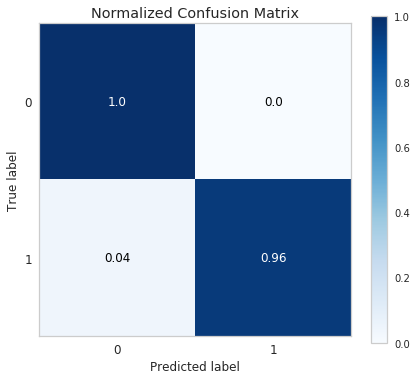

In [34]:
y_pred = grid.predict(X_test)
classes = np.array(['NON_T2D', 'T2D'])

# merge the prediction results as a dataframe named result.
# Create a zipped list of tuples from above lists
zippedList = list(zip(y_test, y_pred))
# Create a dataframe from zipped list
result = pd.DataFrame(zippedList, columns = ['output_label', 'pred_status']) 

print('========== tuned LR with feature selection --trigram ==========')
print(metrics.classification_report(result['output_label'],result['pred_status'],target_names= classes, digits=4))
print("kappa score:", cohen_kappa_score(result['output_label'],result['pred_status'])*100)
print("roc_auc score:", roc_auc_score(result['output_label'],result['pred_status'])*100)

import scikitplot as skplt 
skplt.metrics.plot_confusion_matrix(result['output_label'],result['pred_status'],
                                    normalize=True,figsize=(7, 6))

Comments:

     the LR with Best Params:  {'logisticregression__C': 3.5, 'logisticregression__l1_ratio': 1} obtained the 
     ========== tuned LR with feature selection --trigram ==========
                 precision    recall  f1-score  
    macro avg     0.9661    0.9811    0.9734     
    weighted avg  0.9986    0.9986    0.9986    

    kappa score: 94.68761066854803
    roc_auc score: 98.1068249447299
    

## 2. LinearSVM

============ Best params--lr =========
Best Score:  0.939186661194347
Best Params:  {'calibratedclassifiercv__base_estimator__alpha': 1e-05, 'calibratedclassifiercv__base_estimator__l1_ratio': 0}
========== tuned LR with feature selection --trigram ==========
              precision    recall  f1-score   support

     NON_T2D     0.9992    0.9992    0.9992     52593
         T2D     0.9431    0.9418    0.9424       704

    accuracy                         0.9985     53297
   macro avg     0.9712    0.9705    0.9708     53297
weighted avg     0.9985    0.9985    0.9985     53297

kappa score: 94.16606468825852
roc_auc score: 97.05004030738624


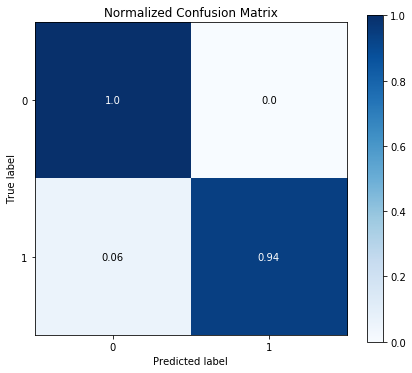

In [54]:
CV = StratifiedKFold(n_splits = 10, shuffle = True, random_state= 42)
tfidf = TfidfVectorizer(stop_words = STOP_WORDS, ngram_range =(1,3))

LinearSVM = SGDClassifier(loss='hinge', penalty= 'elasticnet',random_state=42)
linearSVM_calibrate = CalibratedClassifierCV(LinearSVM, cv= CV) 

pipeline = make_pipeline(tfidf ,linearSVM_calibrate)

param_grid = {'calibratedclassifiercv__base_estimator__l1_ratio':
               [0,0.2,0.5,0.7,1],
              'calibratedclassifiercv__base_estimator__alpha':
               [0.00001,0.00005,0.0001,0.0005]}

grid = GridSearchCV(estimator=pipeline,param_grid = param_grid, n_jobs = -1,
                              iid=False, scoring=kappa_scorer, cv= CV)

grid.fit(X_train, y_train)
print('============ Best params--lr =========')
print("Best Score: ", grid.best_score_)
print("Best Params: ", grid.best_params_)

y_pred = grid.predict(X_test)
classes = np.array(['NON_T2D', 'T2D'])

# merge the prediction results as a dataframe named result.
# Create a zipped list of tuples from above lists
zippedList = list(zip(y_test, y_pred))
# Create a dataframe from zipped list
result = pd.DataFrame(zippedList, columns = ['output_label', 'pred_status']) 

print('========== tuned LR with feature selection --trigram ==========')
print(metrics.classification_report(result['output_label'],result['pred_status'],target_names= classes, digits=4))
print("kappa score:", cohen_kappa_score(result['output_label'],result['pred_status'])*100)
print("roc_auc score:", roc_auc_score(result['output_label'],result['pred_status'])*100)

import scikitplot as skplt 
skplt.metrics.plot_confusion_matrix(result['output_label'],result['pred_status'],
                                    normalize=True,figsize=(7, 6))

Comments;

    the Linear SVM with the Best Params:  {'alpha': 1e-05, 'estimator__l1_ratio': 0}
                   precision    recall  f1-score   support
    macro avg       0.9712    0.9705    0.9708     53297
    weighted avg     0.9985    0.9985    0.9985     53297
    kappa score: 94.16606468825852
    roc_auc score: 97.05004030738624
    
 we can see that the linear SVM is not superior to the Logistic Regression.

## 3. Random forest
tuning the random forest

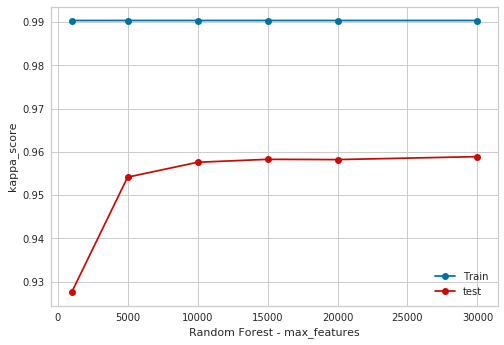

In [84]:
np.random.seed(0)

Cs = [1000,5000,10000,15000,20000,30000]
train_kappa = np.zeros(len(Cs))
test_kappa = np.zeros(len(Cs))

for ii in range(len(Cs)):
    C = Cs[ii]  
    rf = RandomForestClassifier(random_state=42, n_jobs=-1, max_features = C, n_estimators = 300)

    clf = make_pipeline(tfidf_trigram, rf)
    clf.fit(X_train, y_train)

    model = clf
    y_train_preds = model.predict(X_train)
    y_valid_preds = model.predict(X_test)
    kappa_train = cohen_kappa_score(y_train, y_train_preds)
    kappa_valid = cohen_kappa_score(y_test, y_valid_preds)
    train_kappa[ii] = kappa_train
    test_kappa[ii] = kappa_valid
    
plt.plot(Cs, train_kappa,'bo-', label ='Train')
plt.plot(Cs, test_kappa, 'ro-', label='test')
plt.legend()
plt.xlabel('Random Forest - max_features')
plt.ylabel('kappa_score')
plt.show()

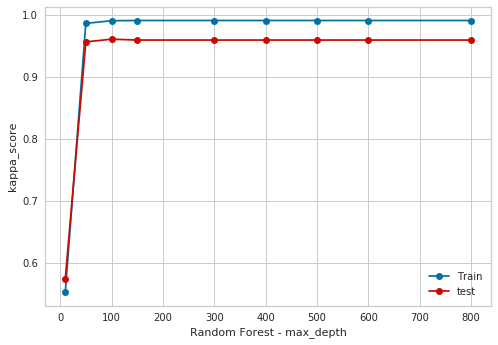

In [89]:
np.random.seed(0)
Cs = [10, 50, 100, 150, 300, 400, 500, 600,800]
train_kappa = np.zeros(len(Cs))
test_kappa = np.zeros(len(Cs))

for ii in range(len(Cs)):
    C = Cs[ii]  
    rf = RandomForestClassifier(random_state=42, n_jobs=-1, max_depth = C, 
                                n_estimators = 300, max_features = 30000)

    clf = make_pipeline(tfidf_trigram, rf)
    clf.fit(X_train, y_train)

    model = clf
    y_train_preds = model.predict(X_train)
    y_valid_preds = model.predict(X_test)
    kappa_train = cohen_kappa_score(y_train, y_train_preds)
    kappa_valid = cohen_kappa_score(y_test, y_valid_preds)
    train_kappa[ii] = kappa_train
    test_kappa[ii] = kappa_valid
    
plt.plot(Cs, train_kappa,'bo-', label ='Train')
plt.plot(Cs, test_kappa, 'ro-', label='test')
plt.legend()
plt.xlabel('Random Forest - max_depth')
plt.ylabel('kappa_score')
plt.show()

============ Best params--RF =========
Best Score:  0.9541428827196442
Best Params:  {'randomforestclassifier__max_depth': 100, 'randomforestclassifier__max_features': 30000}
========== tuned LR with feature selection --trigram ==========
              precision    recall  f1-score   support

     NON_T2D     0.9996    0.9991    0.9994     52593
         T2D     0.9357    0.9716    0.9533       704

    accuracy                         0.9987     53297
   macro avg     0.9677    0.9853    0.9763     53297
weighted avg     0.9988    0.9987    0.9988     53297

kappa score: 95.26732027206667
roc_auc score: 98.5348627020879


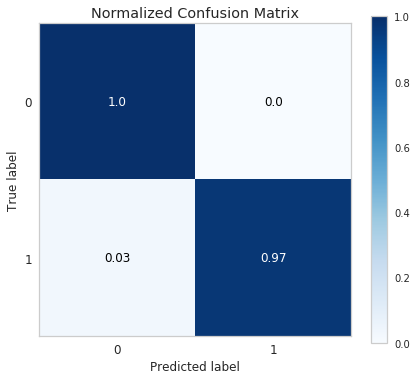

In [90]:
kappa_scorer = make_scorer(cohen_kappa_score)
CV = StratifiedKFold(n_splits = 10, shuffle = True, random_state= 42)
rf = RandomForestClassifier(random_state=42, n_jobs=-1)
tfidf = TfidfVectorizer(stop_words = STOP_WORDS, ngram_range =(1,3))
pipeline = make_pipeline(tfidf, rf)

param = {'randomforestclassifier__max_depth' :[50,100,150],
         'randomforestclassifier__max_features': [15000,20000,25000,30000]
        }

grid = GridSearchCV(pipeline, param_grid = param, scoring = kappa_scorer, cv=CV)

grid.fit(X_train, y_train)
print('============ Best params--RF =========')
print("Best Score: ", grid.best_score_)
print("Best Params: ", grid.best_params_)

y_pred = grid.predict(X_test)
# Create a zipped list of tuples from above lists
zippedList = list(zip(y_test, y_pred))
# Create a dataframe from zipped list
result = pd.DataFrame(zippedList, columns = ['output_label', 'pred_status']) 

print('========== tuned LR with feature selection --trigram ==========')
print(metrics.classification_report(result['output_label'],result['pred_status'],target_names= classes, digits=4))
print("kappa score:", cohen_kappa_score(result['output_label'],result['pred_status'])*100)
print("roc_auc score:", roc_auc_score(result['output_label'],result['pred_status'])*100)

import scikitplot as skplt 
skplt.metrics.plot_confusion_matrix(result['output_label'],result['pred_status'],
                                    normalize=True,figsize=(7, 6))

Comments:
        
     the randomforest with Best Params:  {'max_depth': 100, 'max_features': 30000} obtained the 
     ========== tuned RF  --trigram ==========
                    precision    recall  f1-score   support
    macro avg        0.9677    0.9853    0.9763     53297
    weighted avg     0.9988    0.9987    0.9988     53297

    kappa score: 95.26732027206667
    roc_auc score: 98.5348627020879
    
we can see that it is better than the tuned Logistic regression model.

## 6. Voting  classifier

In [91]:
lr = LogisticRegression(random_state = 42, l1_ratio = 1, C=3.5, solver='saga', penalty = 'elasticnet')

rf =RandomForestClassifier(n_estimators = 300, random_state=42,n_jobs=-1, max_depth = 100, max_features=30000)

LinearSVM = SGDClassifier(loss='hinge', penalty= 'elasticnet', 
                          l1_ratio = 0, alpha = 0.00001, random_state=42)
LinearSVM = CalibratedClassifierCV(LinearSVM, cv= CV) 

tfidf = TfidfVectorizer(stop_words = STOP_WORDS, ngram_range =(1,3))

### soft voting

==========   soft voting   ==========
              precision    recall  f1-score   support

     NON_T2D     0.9995    0.9992    0.9994     52593
         T2D     0.9404    0.9645    0.9523       704

    accuracy                         0.9987     53297
   macro avg     0.9700    0.9818    0.9758     53297
weighted avg     0.9987    0.9987    0.9987     53297

kappa score: 95.1667685404481
roc_auc score: 98.18355185316746


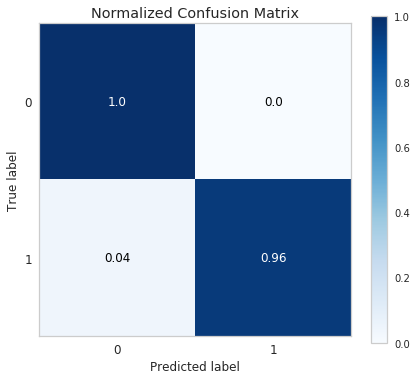

In [92]:
clf1 = make_pipeline(tfidf,  lr)
clf2 = make_pipeline(tfidf, LinearSVM)
clf3 = make_pipeline(tfidf, rf)

voting_soft = VotingClassifier([('lr', clf1),('linearsvm', clf2),
                                ('rf',clf3)], voting='soft')

voting_soft.fit(X_train, y_train)
y_pred = voting_soft.predict(X_test)
classes = np.array(['NON_T2D', 'T2D'])

# merge the prediction results as a dataframe named result.
# Create a zipped list of tuples from above lists
zippedList = list(zip(y_test, y_pred))
# Create a dataframe from zipped list
result = pd.DataFrame(zippedList, columns = ['output_label', 'pred_status']) 

print('==========   soft voting   ==========')
print(metrics.classification_report(result['output_label'],result['pred_status'],target_names= classes, digits=4))
print("kappa score:", cohen_kappa_score(result['output_label'],result['pred_status'])*100)
print("roc_auc score:", roc_auc_score(result['output_label'],result['pred_status'])*100)

import scikitplot as skplt 
skplt.metrics.plot_confusion_matrix(result['output_label'],result['pred_status'],
                                    normalize=True,figsize=(7, 6))

Comments:
        
     ==========   soft voting   ==========
                    precision    recall  f1-score   support
     macro avg       0.9700    0.9818    0.9758     53297
     weighted avg     0.9987    0.9987    0.9987     53297
     kappa score: 95.1667685404481
     roc_auc score: 98.18355185316746
    
we can see that the soft voting method does not improve the performance.

### hard voting with weight

========== hard voting  ==========
              precision    recall  f1-score   support

     NON_T2D     0.9995    0.9993    0.9994     52593
         T2D     0.9456    0.9631    0.9543       704

    accuracy                         0.9988     53297
   macro avg     0.9726    0.9812    0.9768     53297
weighted avg     0.9988    0.9988    0.9988     53297

kappa score: 95.36395881775353
roc_auc score: 98.11633191333793


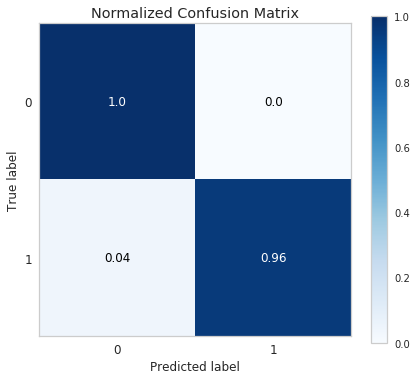

In [93]:
voting_hard = VotingClassifier([('lr', clf1),('linearsvm', clf2),
                                ('rf',clf3)], voting='hard')

voting_hard.fit(X_train, y_train)

y_pred = voting_hard.predict(X_test)
classes = np.array(['NON_T2D', 'T2D'])

# merge the prediction results as a dataframe named result.
# Create a zipped list of tuples from above lists
zippedList = list(zip(y_test, y_pred))
# Create a dataframe from zipped list
result = pd.DataFrame(zippedList, columns = ['output_label', 'pred_status']) 

print('========== hard voting  ==========')
print(metrics.classification_report(result['output_label'],result['pred_status'],target_names= classes, digits=4))
print("kappa score:", cohen_kappa_score(result['output_label'],result['pred_status'])*100)
print("roc_auc score:", roc_auc_score(result['output_label'],result['pred_status'])*100)

import scikitplot as skplt 
skplt.metrics.plot_confusion_matrix(result['output_label'],result['pred_status'],
                                    normalize=True,figsize=(7, 6))

Comments:
        
     ==========   soft voting   ==========
                    precision    recall  f1-score   support
     macro avg     0.9726    0.9812    0.9768     53297
     weighted avg     0.9988    0.9988    0.9988     53297
     kappa score: 95.36395881775353
     roc_auc score: 98.11633191333793
    
the hard voting improve the final result which is better than the random forest. Therefore, the hard voting of LR, LINEAR SVM AND RF is determined.

After that, the resampling methods were explored including SMOTE, random oversampling and random under sampling.

# Step 6 : Resampling method

In this section we tried Resampling: 


##  a. RandomOverSampler and SMOTE 

In [24]:
from imblearn.pipeline import make_pipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler

lr = LogisticRegression(random_state = 42)

tfidf = TfidfVectorizer(stop_words = STOP_WORDS, ngram_range =(1,3))

ROS_pipeline = make_pipeline(tfidf, RandomOverSampler(random_state=42),lr)
SMOTE_pipeline = make_pipeline(tfidf, SMOTE(random_state=42),lr)

print('===== the RandomOverSampler======')
cv(10, X_train, y_train, ROS_pipeline)
print('===== the SMOTE ======')
cv(10, X_train, y_train, SMOTE_pipeline)

===== the RandomOverSampler======
precision: 78.53% (+/- 2.01%)
recall: 98.78% (+/- 0.97%)
f1 score: 87.48% (+/- 1.29%)
kappa score: 87.29% (+/- 1.31%)
roc_auc score: 99.21% (+/- 0.48%)
===== the SMOTE ======
precision: 81.99% (+/- 1.85%)
recall: 97.66% (+/- 1.31%)
f1 score: 89.13% (+/- 1.32%)
kappa score: 88.97% (+/- 1.34%)
roc_auc score: 98.69% (+/- 0.66%)


In [25]:
# the oversampling with strategy = {1: 15000}
strategy = {1: 15000}
ROS_pipeline = make_pipeline(tfidf, RandomOverSampler(random_state=42, sampling_strategy = strategy),lr)
SMOTE_pipeline = make_pipeline(tfidf, SMOTE(random_state=42, sampling_strategy = strategy),lr)

print('===== the RandomOverSampler======')
cv(10, X_train, y_train, ROS_pipeline)
print('===== the SMOTE ======')
cv(10, X_train, y_train, SMOTE_pipeline)

===== the RandomOverSampler======
precision: 87.46% (+/- 1.82%)
recall: 95.75% (+/- 1.48%)
f1 score: 91.41% (+/- 1.41%)
kappa score: 91.29% (+/- 1.43%)
roc_auc score: 97.78% (+/- 0.75%)
===== the SMOTE ======
precision: 89.31% (+/- 1.71%)
recall: 93.44% (+/- 1.82%)
f1 score: 91.32% (+/- 1.56%)
kappa score: 91.21% (+/- 1.59%)
roc_auc score: 96.65% (+/- 0.92%)


In [53]:
# the oversampling with strategy = {1: 30000}
strategy = {1: 30000}
ROS_pipeline = make_pipeline(tfidf, RandomOverSampler(random_state=42, sampling_strategy = strategy),lr)
SMOTE_pipeline = make_pipeline(tfidf, SMOTE(random_state=42, sampling_strategy = strategy),lr)

print('===== the RandomOverSampler======')
cv(10, X_train, y_train, ROS_pipeline)
print('===== the SMOTE ======')
cv(10, X_train, y_train, SMOTE_pipeline)

===== the RandomOverSampler======
precision: 85.07% (+/- 1.94%)
recall: 97.19% (+/- 1.36%)
f1 score: 90.71% (+/- 1.37%)
kappa score: 90.58% (+/- 1.39%)
roc_auc score: 98.48% (+/- 0.68%)
===== the SMOTE ======
precision: 87.71% (+/- 1.73%)
recall: 95.14% (+/- 1.77%)
f1 score: 91.26% (+/- 1.40%)
kappa score: 91.14% (+/- 1.42%)
roc_auc score: 97.48% (+/- 0.89%)


In [54]:
# the oversampling with strategy = {1: 50000}
strategy = {1: 50000}
ROS_pipeline = make_pipeline(tfidf, RandomOverSampler(random_state=42, sampling_strategy = strategy),lr)
SMOTE_pipeline = make_pipeline(tfidf, SMOTE(random_state=42, sampling_strategy = strategy),lr)

print('===== the RandomOverSampler======')
cv(10, X_train, y_train, ROS_pipeline)
print('===== the SMOTE ======')
cv(10, X_train, y_train, SMOTE_pipeline)

===== the RandomOverSampler======
precision: 83.20% (+/- 2.04%)
recall: 97.62% (+/- 1.40%)
f1 score: 89.82% (+/- 1.46%)
kappa score: 89.68% (+/- 1.49%)
roc_auc score: 98.68% (+/- 0.70%)
===== the SMOTE ======
precision: 86.26% (+/- 2.01%)
recall: 96.22% (+/- 1.51%)
f1 score: 90.95% (+/- 1.43%)
kappa score: 90.83% (+/- 1.45%)
roc_auc score: 98.01% (+/- 0.76%)


## b. RandomUnderSampler

In [27]:
from imblearn.under_sampling import NearMiss, RandomUnderSampler

RUS_pipeline = make_pipeline(tfidf, RandomUnderSampler(random_state=42),lr)

print('===== the Random underSampler======')
cv(10, X_train, y_train, RUS_pipeline)

===== the Random underSampler======
precision: 62.48% (+/- 2.04%)
recall: 97.88% (+/- 1.36%)
f1 score: 76.24% (+/- 1.36%)
kappa score: 75.86% (+/- 1.39%)
roc_auc score: 98.55% (+/- 0.66%)


## the combination of over samplier and random undersampler.

In [30]:
strategy1 = {0: 15000}
strategy2 = {1: 15000}

lr = LogisticRegression(random_state = 42)
tfidf = TfidfVectorizer(stop_words = STOP_WORDS, ngram_range =(1,3))

COM_ROS_pipe = make_pipeline(tfidf, RandomUnderSampler(random_state=42,sampling_strategy = strategy1),
                             RandomOverSampler(random_state=42, sampling_strategy = strategy2),lr)
COM_SMOTE_pipe = make_pipeline(tfidf,  RandomUnderSampler(random_state=42,sampling_strategy = strategy1),
                               SMOTE(random_state=42, sampling_strategy = strategy2),lr)

print('===== the RUS and random over sampler======')
cv(10, X_train, y_train, COM_ROS_pipe)

print('===== the RUS and smote======')
cv(10, X_train, y_train, COM_SMOTE_pipe)

===== the RUS and random over sampler======
precision: 65.12% (+/- 2.23%)
recall: 98.67% (+/- 1.04%)
f1 score: 78.42% (+/- 1.50%)
kappa score: 78.08% (+/- 1.53%)
roc_auc score: 98.98% (+/- 0.50%)
===== the RUS and smote======
precision: 70.16% (+/- 2.41%)
recall: 97.55% (+/- 1.24%)
f1 score: 81.59% (+/- 1.51%)
kappa score: 81.30% (+/- 1.54%)
roc_auc score: 98.50% (+/- 0.60%)


## Result
    The 10-fold cross validation results shows that the method randomOverSampler with strategy = {1: 15000} has the highest performance. Hence, different classifiers will be tried based on the after balanced data set with randomOverSampler method. 

## Logistic Regression with randomOverSampler

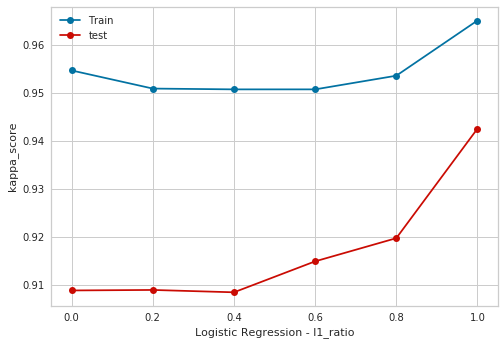

In [57]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
np.random.seed(0)
kappa_scorer = make_scorer(cohen_kappa_score)
strategy = {1: 15000}

l1_ratio = [0,0.2,0.4,0.6,0.8,1]
train_kappa = np.zeros(len(l1_ratio))
test_kappa = np.zeros(len(l1_ratio))

for ii in range(len(l1_ratio)):
    ratio = l1_ratio[ii]  
   
    # logistic regression
    lr = LogisticRegression(l1_ratio = ratio, random_state = 42,solver='saga', penalty = 'elasticnet')
    clf = make_pipeline(tfidf_trigram, RandomOverSampler(random_state=42, sampling_strategy = strategy),lr)
    clf.fit(X_train, y_train)

    model = clf
    y_train_preds = model.predict(X_train)
    y_valid_preds = model.predict(X_test)
    kappa_train = cohen_kappa_score(y_train, y_train_preds)
    kappa_valid = cohen_kappa_score(y_test, y_valid_preds)
    train_kappa[ii] = kappa_train
    test_kappa[ii] = kappa_valid
    
plt.plot(l1_ratio, train_kappa,'bo-', label ='Train')
plt.plot(l1_ratio, test_kappa, 'ro-', label='test')
plt.legend()
plt.xlabel('Logistic Regression - l1_ratio')
plt.ylabel('kappa_score')
plt.show()

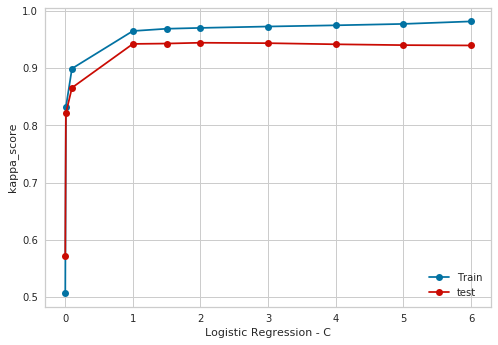

In [58]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
np.random.seed(0)
kappa_scorer = make_scorer(cohen_kappa_score)

Cs = [0.001, 0.01, 0.1, 1, 1.5, 2, 3, 4, 5, 6]
train_kappa = np.zeros(len(Cs))
test_kappa = np.zeros(len(Cs))

for ii in range(len(Cs)):
    C = Cs[ii]  
   
    # logistic regression
    lr = LogisticRegression(C = C, l1_ratio = 1, random_state = 42,solver='saga', penalty = 'elasticnet')
    clf = make_pipeline(tfidf_trigram, RandomOverSampler(random_state=42, sampling_strategy = strategy),lr)
    clf.fit(X_train, y_train)

    model = clf
    y_train_preds = model.predict(X_train)
    y_valid_preds = model.predict(X_test)
    kappa_train = cohen_kappa_score(y_train, y_train_preds)
    kappa_valid = cohen_kappa_score(y_test, y_valid_preds)
    train_kappa[ii] = kappa_train
    test_kappa[ii] = kappa_valid
    
plt.plot(Cs, train_kappa,'bo-', label ='Train')
plt.plot(Cs, test_kappa, 'ro-', label='test')
plt.legend()
plt.xlabel('Logistic Regression - C')
plt.ylabel('kappa_score')
plt.show()

============ Best params--lr =========
Best Score:  0.9986973028031766
Best Params:  {'logisticregression__C': 1, 'logisticregression__l1_ratio': 1}
========== tuned LR with ROS --trigram ==========
              precision    recall  f1-score   support

     NON_T2D     0.9998    0.9987    0.9992     52593
         T2D     0.9080    0.9815    0.9433       704

    accuracy                         0.9984     53297
   macro avg     0.9539    0.9901    0.9713     53297
weighted avg     0.9985    0.9984    0.9985     53297

kappa score: 94.25564154723101
roc_auc score: 99.01015576519862


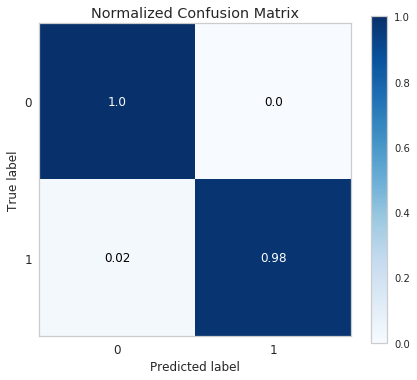

In [98]:
CV = StratifiedKFold(n_splits = 10, shuffle = True, random_state= 42)

tfidf_trigram = TfidfVectorizer(stop_words = STOP_WORDS, ngram_range =(1,3))
lr_elastic = LogisticRegression(random_state = 42, solver='saga', penalty = 'elasticnet')

pipe_lr = make_pipeline(tfidf_trigram, RandomOverSampler(random_state=42, sampling_strategy = strategy),
                        lr_elastic)

param_grid = { 'logisticregression__l1_ratio':[0.8,0.9,1],
               'logisticregression__C': [1,2,3]}
    
grid = GridSearchCV(pipe_lr ,param_grid, n_jobs = -1,iid=False, scoring="roc_auc", cv= CV)

grid.fit(X_train, y_train)
print('============ Best params--lr =========')
print("Best Score: ", grid.best_score_)
print("Best Params: ", grid.best_params_)

y_pred = grid.predict(X_test)
# Create a zipped list of tuples from above lists
zippedList = list(zip(y_test, y_pred))
# Create a dataframe from zipped list
result = pd.DataFrame(zippedList, columns = ['output_label', 'pred_status']) 

print('========== tuned LR with ROS --trigram ==========')
print(metrics.classification_report(result['output_label'],result['pred_status'],target_names= classes, digits=4))
print("kappa score:", cohen_kappa_score(result['output_label'],result['pred_status'])*100)
print("roc_auc score:", roc_auc_score(result['output_label'],result['pred_status'])*100)

import scikitplot as skplt 
skplt.metrics.plot_confusion_matrix(result['output_label'],result['pred_status'],
                                    normalize=True,figsize=(7, 6))

## LinearSVM with randomOverSampler

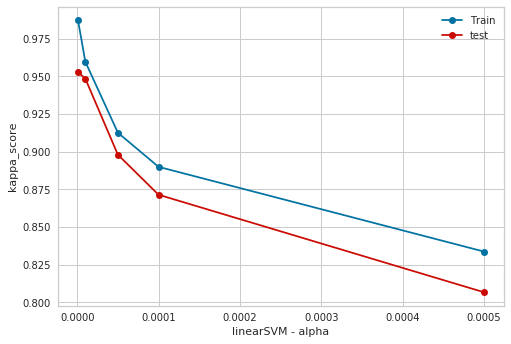

In [70]:
np.random.seed(0)

Cs = [0.00001, 0.00005, 0.0001, 0.0005]
train_kappa = np.zeros(len(Cs))
test_kappa = np.zeros(len(Cs))

for ii in range(len(Cs)):
    C = Cs[ii]  
    LinearSVM = SGDClassifier(alpha = C, l1_ratio = 0.5, loss='hinge', penalty= 'elasticnet',random_state=42)
    linearSVM_calibrate = CalibratedClassifierCV(LinearSVM, cv= CV) 

    clf = make_pipeline(tfidf_trigram, RandomOverSampler(random_state=42, sampling_strategy = strategy),
                        linearSVM_calibrate)
    clf.fit(X_train, y_train)

    model = clf
    y_train_preds = model.predict(X_train)
    y_valid_preds = model.predict(X_test)
    kappa_train = cohen_kappa_score(y_train, y_train_preds)
    kappa_valid = cohen_kappa_score(y_test, y_valid_preds)
    train_kappa[ii] = kappa_train
    test_kappa[ii] = kappa_valid
    
plt.plot(Cs, train_kappa,'bo-', label ='Train')
plt.plot(Cs, test_kappa, 'ro-', label='test')
plt.legend()
plt.xlabel('linearSVM - alpha')
plt.ylabel('kappa_score')
plt.show()

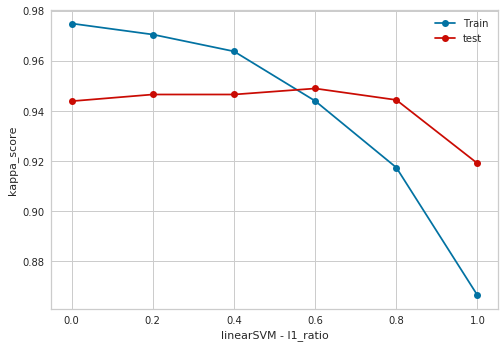

In [75]:
np.random.seed(0)
l1_ratio = [0,0.2,0.4,0.6,0.8,1]
train_kappa = np.zeros(len(l1_ratio))
test_kappa = np.zeros(len(l1_ratio))

for ii in range(len(l1_ratio)):
    ratio = l1_ratio[ii]  
    LinearSVM = SGDClassifier(l1_ratio = ratio, loss='hinge', penalty= 'elasticnet',
                              random_state=42,alpha = 0.00001)
    linearSVM_calibrate = CalibratedClassifierCV(LinearSVM, cv= CV) 

    clf = make_pipeline(tfidf_trigram, RandomOverSampler(random_state=42, sampling_strategy = strategy),
                        linearSVM_calibrate)
    clf.fit(X_train, y_train)

    model = clf
    y_train_preds = model.predict(X_train)
    y_valid_preds = model.predict(X_test)
    kappa_train = cohen_kappa_score(y_train, y_train_preds)
    kappa_valid = cohen_kappa_score(y_test, y_valid_preds)
    train_kappa[ii] = kappa_train
    test_kappa[ii] = kappa_valid
    
plt.plot(l1_ratio, train_kappa,'bo-', label ='Train')
plt.plot(l1_ratio, test_kappa, 'ro-', label='test')
plt.legend()
plt.xlabel('linearSVM - l1_ratio')
plt.ylabel('kappa_score')
plt.show()

============ Best params--lr =========
Best Score:  0.9475247278421512
Best Params:  {'calibratedclassifiercv__base_estimator__alpha': 1e-05, 'calibratedclassifiercv__base_estimator__l1_ratio': 0.6}
========== tuned LinearSVM with ros --trigram ==========
              precision    recall  f1-score   support

     NON_T2D     0.9995    0.9991    0.9993     52593
         T2D     0.9353    0.9645    0.9497       704

    accuracy                         0.9986     53297
   macro avg     0.9674    0.9818    0.9745     53297
weighted avg     0.9987    0.9986    0.9987     53297

kappa score: 94.89658689639028
roc_auc score: 98.17974906572425


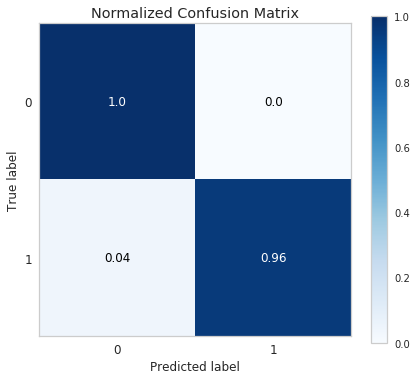

In [99]:
CV = StratifiedKFold(n_splits = 10, shuffle = True, random_state= 42)
tfidf = TfidfVectorizer(stop_words = STOP_WORDS, ngram_range =(1,3))

LinearSVM = SGDClassifier(loss='hinge', penalty= 'elasticnet',random_state=42)
linearSVM_calibrate = CalibratedClassifierCV(LinearSVM, cv= CV) 

pipeline = make_pipeline(tfidf ,RandomOverSampler(random_state=42, sampling_strategy = strategy),
                         linearSVM_calibrate)

param_grid = {'calibratedclassifiercv__base_estimator__l1_ratio':
               [0,0.5,0.6,0.7],
              'calibratedclassifiercv__base_estimator__alpha':
               [0.00001,0.0001]}

grid = GridSearchCV(pipeline, param_grid, n_jobs = -1, iid=False, scoring=kappa_scorer, cv= CV)

grid.fit(X_train, y_train)
print('============ Best params--lr =========')
print("Best Score: ", grid.best_score_)
print("Best Params: ", grid.best_params_)

y_pred = grid.predict(X_test)
classes = np.array(['NON_T2D', 'T2D'])

# merge the prediction results as a dataframe named result.
# Create a zipped list of tuples from above lists
zippedList = list(zip(y_test, y_pred))
# Create a dataframe from zipped list
result = pd.DataFrame(zippedList, columns = ['output_label', 'pred_status']) 

print('========== tuned LinearSVM with ros --trigram ==========')
print(metrics.classification_report(result['output_label'],result['pred_status'],target_names= classes, digits=4))
print("kappa score:", cohen_kappa_score(result['output_label'],result['pred_status'])*100)
print("roc_auc score:", roc_auc_score(result['output_label'],result['pred_status'])*100)

import scikitplot as skplt 
skplt.metrics.plot_confusion_matrix(result['output_label'],result['pred_status'],
                                    normalize=True,figsize=(7, 6))

## rf with randomOverSampler

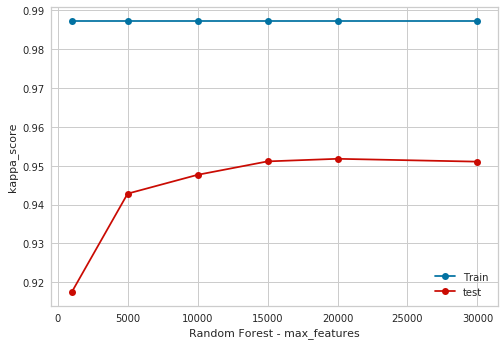

In [79]:
np.random.seed(0)

Cs = [1000,5000,10000,15000,20000,30000]
train_kappa = np.zeros(len(Cs))
test_kappa = np.zeros(len(Cs))

for ii in range(len(Cs)):
    C = Cs[ii]  
    rf = RandomForestClassifier(random_state=42, n_jobs=-1, max_features = C, n_estimators = 300)

    clf = make_pipeline(tfidf_trigram, RandomOverSampler(random_state=42, sampling_strategy = strategy), rf)
    clf.fit(X_train, y_train)

    model = clf
    y_train_preds = model.predict(X_train)
    y_valid_preds = model.predict(X_test)
    kappa_train = cohen_kappa_score(y_train, y_train_preds)
    kappa_valid = cohen_kappa_score(y_test, y_valid_preds)
    train_kappa[ii] = kappa_train
    test_kappa[ii] = kappa_valid
    
plt.plot(Cs, train_kappa,'bo-', label ='Train')
plt.plot(Cs, test_kappa, 'ro-', label='test')
plt.legend()
plt.xlabel('Random Forest - max_features')
plt.ylabel('kappa_score')
plt.show()

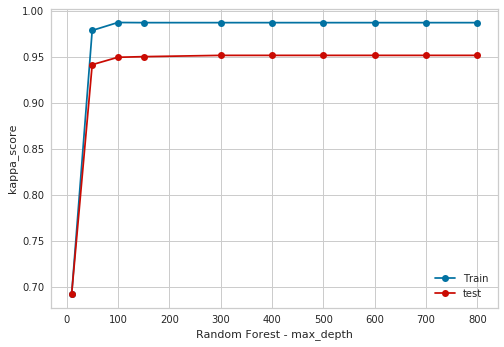

In [81]:
np.random.seed(0)
Cs = [10, 50, 100, 150, 300, 400, 500, 600,700,800]
train_kappa = np.zeros(len(Cs))
test_kappa = np.zeros(len(Cs))

for ii in range(len(Cs)):
    C = Cs[ii]  
    rf = RandomForestClassifier(random_state=42, n_jobs=-1, max_depth = C, 
                                n_estimators = 300, max_features = 20000)

    clf = make_pipeline(tfidf_trigram, RandomOverSampler(random_state=42, sampling_strategy = strategy), rf)
    clf.fit(X_train, y_train)

    model = clf
    y_train_preds = model.predict(X_train)
    y_valid_preds = model.predict(X_test)
    kappa_train = cohen_kappa_score(y_train, y_train_preds)
    kappa_valid = cohen_kappa_score(y_test, y_valid_preds)
    train_kappa[ii] = kappa_train
    test_kappa[ii] = kappa_valid
    
plt.plot(Cs, train_kappa,'bo-', label ='Train')
plt.plot(Cs, test_kappa, 'ro-', label='test')
plt.legend()
plt.xlabel('Random Forest - max_depth')
plt.ylabel('kappa_score')
plt.show()

============ Best params--RF =========
Best Score:  0.9367264171856597
Best Params:  {'randomforestclassifier__max_depth': 300, 'randomforestclassifier__max_features': 20000}
========== rf with ros --trigram ==========
              precision    recall  f1-score   support

     NON_T2D     0.9997    0.9989    0.9993     52593
         T2D     0.9211    0.9787    0.9490       704

    accuracy                         0.9986     53297
   macro avg     0.9604    0.9888    0.9742     53297
weighted avg     0.9987    0.9986    0.9986     53297

kappa score: 94.83326577939127
roc_auc score: 98.87856797612194


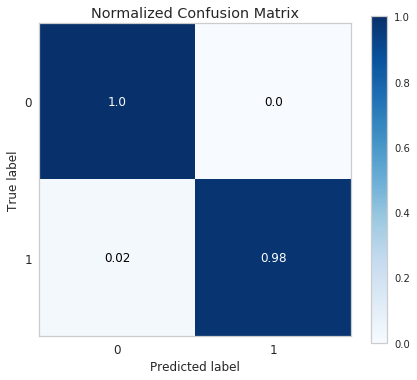

In [101]:
kappa_scorer = make_scorer(cohen_kappa_score)
CV = StratifiedKFold(n_splits = 10, shuffle = True, random_state= 42)
rf = RandomForestClassifier(random_state=42, n_jobs=-1)
tfidf = TfidfVectorizer(stop_words = STOP_WORDS, ngram_range =(1,3))
pipeline = make_pipeline(tfidf, RandomOverSampler(random_state=42, sampling_strategy = strategy),rf)

param = {'randomforestclassifier__max_depth' :[200,250,300,350],
         'randomforestclassifier__max_features': [5000,10000,15000,20000]
        }

grid = GridSearchCV(pipeline, param_grid = param, scoring = kappa_scorer, cv=CV)

grid.fit(X_train, y_train)
print('============ Best params--RF =========')
print("Best Score: ", grid.best_score_)
print("Best Params: ", grid.best_params_)

y_pred = grid.predict(X_test)
# Create a zipped list of tuples from above lists
zippedList = list(zip(y_test, y_pred))
# Create a dataframe from zipped list
result = pd.DataFrame(zippedList, columns = ['output_label', 'pred_status']) 

print('========== rf with ros --trigram ==========')
print(metrics.classification_report(result['output_label'],result['pred_status'],target_names= classes, digits=4))
print("kappa score:", cohen_kappa_score(result['output_label'],result['pred_status'])*100)
print("roc_auc score:", roc_auc_score(result['output_label'],result['pred_status'])*100)

import scikitplot as skplt 
skplt.metrics.plot_confusion_matrix(result['output_label'],result['pred_status'],
                                    normalize=True,figsize=(7, 6))

## d) Voting  classifier

In [102]:
lr_elastic = LogisticRegression(C= 1, random_state = 42, solver='saga', penalty = 'elasticnet',l1_ratio = 1)

rf = RandomForestClassifier(n_estimators = 300, random_state=42,
                            n_jobs=-1,max_depth = 300, max_features = 20000)

LinearSVM = SGDClassifier(loss='hinge', penalty= 'elasticnet',random_state=42, l1_ratio = 0.6, alpha = 0.00001)
linearSVM_calibrate = CalibratedClassifierCV(LinearSVM, cv= CV) 

tfidf = TfidfVectorizer(stop_words = STOP_WORDS, ngram_range =(1,3))

### soft voting

==========   soft voting   ==========
              precision    recall  f1-score   support

     NON_T2D     0.9997    0.9990    0.9994     52593
         T2D     0.9287    0.9801    0.9537       704

    accuracy                         0.9987     53297
   macro avg     0.9642    0.9896    0.9765     53297
weighted avg     0.9988    0.9987    0.9988     53297

kappa score: 95.30605708619098
roc_auc score: 98.95529488455946


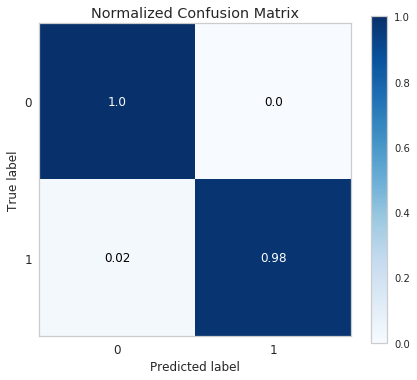

In [104]:
clf1 = make_pipeline(tfidf, RandomOverSampler(random_state=42, sampling_strategy = strategy),lr)
clf2 = make_pipeline(tfidf, RandomOverSampler(random_state=42, sampling_strategy = strategy),linearSVM_calibrate)
clf3 = make_pipeline(tfidf, RandomOverSampler(random_state=42, sampling_strategy = strategy),rf)

voting_soft = VotingClassifier([('lr', clf1),('linearsvm', clf2),
                                ('rf',clf3)], voting='soft')

voting_soft.fit(X_train, y_train)
y_pred = voting_soft.predict(X_test)

# Create a zipped list of tuples from above lists
zippedList = list(zip(y_test, y_pred))
# Create a dataframe from zipped list
result = pd.DataFrame(zippedList, columns = ['output_label', 'pred_status']) 

print('==========   soft voting   ==========')
print(metrics.classification_report(result['output_label'],result['pred_status'],target_names= classes, digits=4))
print("kappa score:", cohen_kappa_score(result['output_label'],result['pred_status'])*100)
print("roc_auc score:", roc_auc_score(result['output_label'],result['pred_status'])*100)

import scikitplot as skplt 
skplt.metrics.plot_confusion_matrix(result['output_label'],result['pred_status'],
                                    normalize=True,figsize=(7, 6))

### hard voting with weight

========== hard voting  ==========
              precision    recall  f1-score   support

     NON_T2D     0.9997    0.9990    0.9993     52593
         T2D     0.9262    0.9801    0.9524       704

    accuracy                         0.9987     53297
   macro avg     0.9630    0.9895    0.9759     53297
weighted avg     0.9988    0.9987    0.9987     53297

kappa score: 95.17252483916273
roc_auc score: 98.95339349083787


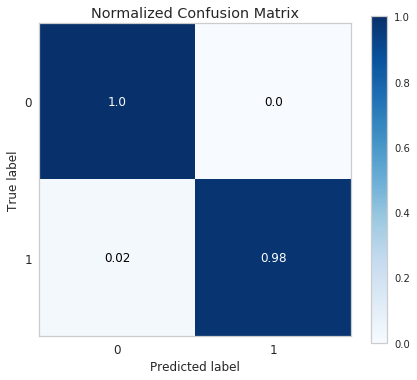

In [105]:
voting_hard = VotingClassifier([('lr', clf1),('linearsvm', clf2),
                                ('rf',clf3)], voting='hard')

voting_hard.fit(X_train, y_train)

y_pred = voting_hard.predict(X_test)

# Create a zipped list of tuples from above lists
zippedList = list(zip(y_test, y_pred))
# Create a dataframe from zipped list
result = pd.DataFrame(zippedList, columns = ['output_label', 'pred_status']) 

print('========== hard voting  ==========')
print(metrics.classification_report(result['output_label'],result['pred_status'],target_names= classes, digits=4))
print("kappa score:", cohen_kappa_score(result['output_label'],result['pred_status'])*100)
print("roc_auc score:", roc_auc_score(result['output_label'],result['pred_status'])*100)

import scikitplot as skplt 
skplt.metrics.plot_confusion_matrix(result['output_label'],result['pred_status'],
                                    normalize=True,figsize=(7, 6))

Comments: 

it can be found that the soft voing got the best result.

# Step7 - Deep learning models
##  LSTM Model

In [25]:
import tensorflow
import keras
from keras.preprocessing.text import Tokenizer
from keras.preprocessing.sequence import pad_sequences
from keras.models import Sequential
from keras.layers import Dense, Embedding, LSTM, SpatialDropout1D
from keras.utils.np_utils import to_categorical
from keras.callbacks import EarlyStopping
from keras.layers import Dropout
from keras.preprocessing import sequence

In [26]:
y_test_lstm = pd.get_dummies(y_test).values
print('Shape of label tensor:', y_test_lstm.shape)
y_train_lstm = pd.get_dummies(y_train).values
print('Shape of label tensor:', y_train_lstm.shape)

Shape of label tensor: (53297, 2)
Shape of label tensor: (213189, 2)


In [27]:
# LSTM for sequence classification 
# fix random seed for reproducibility
from tensorflow import random
random.set_seed(42)
np.random.seed(42)
# load the dataset but only keep the top n words, zero the rest
top_words = 10000
# truncate and pad input sequences
max_review_length = 1500
# create the model
embedding_vecor_length = 150

### remove stop words
def filter_stop_words(train_sentences, STOP_WORDS):
    for i, sentence in enumerate(train_sentences):
        new_sent = [word for word in sentence.split() if word not in STOP_WORDS]
        train_sentences[i] = ' '.join(new_sent)
    return train_sentences

train_sentences = filter_stop_words(X_train, STOP_WORDS)

tokenizer = Tokenizer(num_words=top_words, filters='!"#$%&()*+,-./:;<=>?@[\]^_`{|}~')
tokenizer.fit_on_texts(train_sentences)
word_index = tokenizer.word_index
print('Found %s unique tokens.' % len(train_sentences))

Found 213189 unique tokens.


In [28]:
X_train_lstm = tokenizer.texts_to_sequences(train_sentences)
X_train_lstm  = pad_sequences(X_train_lstm , maxlen=max_review_length)
print('Shape of data tensor:', X_train_lstm.shape)

Shape of data tensor: (213189, 1500)


In [39]:
test_sentences = filter_stop_words(X_test, STOP_WORDS)
X_test_lstm = tokenizer.texts_to_sequences(test_sentences)
X_test_lstm  = pad_sequences(X_test_lstm , maxlen=max_review_length)
print('Shape of data tensor:', X_test_lstm.shape)

Shape of data tensor: (53297, 1500)


In [50]:
model = Sequential()
model.add(Embedding(top_words, embedding_vecor_length, input_length= max_review_length))
#model.add(SpatialDropout1D(0.2))
model.add(LSTM(5))
model.add(Dense(2,activation='sigmoid'))
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['acc'])

print(model.summary())
history= model.fit(X_train_lstm, y_train_lstm, epochs= 20, batch_size= 512, validation_split=0.2)

Model: "sequential_11"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_11 (Embedding)     (None, 1500, 150)         1500000   
_________________________________________________________________
lstm_11 (LSTM)               (None, 5)                 3120      
_________________________________________________________________
dense_11 (Dense)             (None, 2)                 12        
Total params: 1,503,132
Trainable params: 1,503,132
Non-trainable params: 0
_________________________________________________________________
None
Train on 170551 samples, validate on 42638 samples
Epoch 1/20
170551/170551 [==============================] - 968s 6ms/step - loss: 0.1888 - acc: 0.9856 - val_loss: 0.0607 - val_acc: 0.9933
Epoch 2/20
170551/170551 [==============================] - 1024s 6ms/step - loss: 0.0398 - acc: 0.9963 - val_loss: 0.0278 - val_acc: 0.9967
Epoch 3/20
170551/170551 [==========

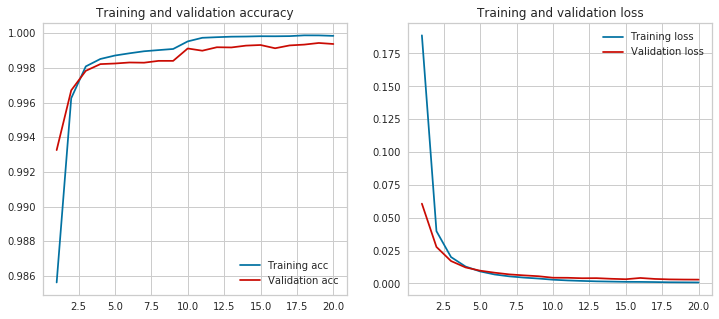

In [51]:
import matplotlib.pyplot as plt

def plot_history(history):
    acc = history.history['acc']
    val_acc = history.history['val_acc']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    x = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(x, acc, 'b', label='Training acc')
    plt.plot(x, val_acc, 'r', label='Validation acc')
    plt.title('Training and validation accuracy')
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(x, loss, 'b', label='Training loss')
    plt.plot(x, val_loss, 'r', label='Validation loss')
    plt.title('Training and validation loss')
    plt.legend()
    
plot_history(history)

========== lstm classification ==========
              precision    recall  f1-score   support

           0     0.9997    0.9997    0.9997     52593
           1     0.9773    0.9801    0.9787       704

    accuracy                         0.9994     53297
   macro avg     0.9885    0.9899    0.9892     53297
weighted avg     0.9994    0.9994    0.9994     53297

kappa score: 97.84381903555649


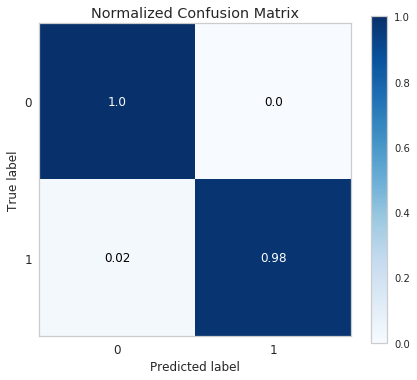

In [52]:
pred_lstm = model.predict(X_test_lstm)
pred_lstm = pd.DataFrame(pred_lstm, columns = [0,1])
pred_lstm['final'] = pred_lstm[[0,1]].idxmax(axis = 1)
pred_lstm1 = pred_lstm['final'] 

zippedList = list(zip(y_test, pred_lstm1))
result = pd.DataFrame(zippedList, columns = ['output_label', 'pred_status']) 

print('========== lstm classification ==========')
print(metrics.classification_report(result['output_label'],result['pred_status'], digits=4))
print("kappa score:", cohen_kappa_score(result['output_label'],result['pred_status'])*100)

import scikitplot as skplt 
skplt.metrics.plot_confusion_matrix(result['output_label'],result['pred_status'],
                                    normalize=True,figsize=(7, 6))

In [55]:
print("roc_auc score:", roc_auc_score(result['output_label'],result['pred_status'])*100)

roc_auc score: 98.99047066840903
